# Task 1: Multi-Class Classification Pipeline

## Objective
Build and compare Logistic Regression and Decision Tree
models using the Iris dataset.

## Key Steps
- Exploratory Data Analysis (EDA)
- Train-test split (80:20)
- Feature scaling using StandardScaler
- Model training and evaluation
- Confusion matrix visualization

In [17]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [18]:
# Load the Iris dataset

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nSpecies distribution:")
print(df["species"].value_counts())

Dataset loaded successfully!

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Dataset shape: (150, 5)

Column names:
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [19]:
# Exploratory Data Analysis (EDA)

# Summary statistics for numerical columns
display(df.describe())

# Count the number of flowers in each species
print("Species Counts:")
print(df["species"].value_counts())

,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


Species Counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


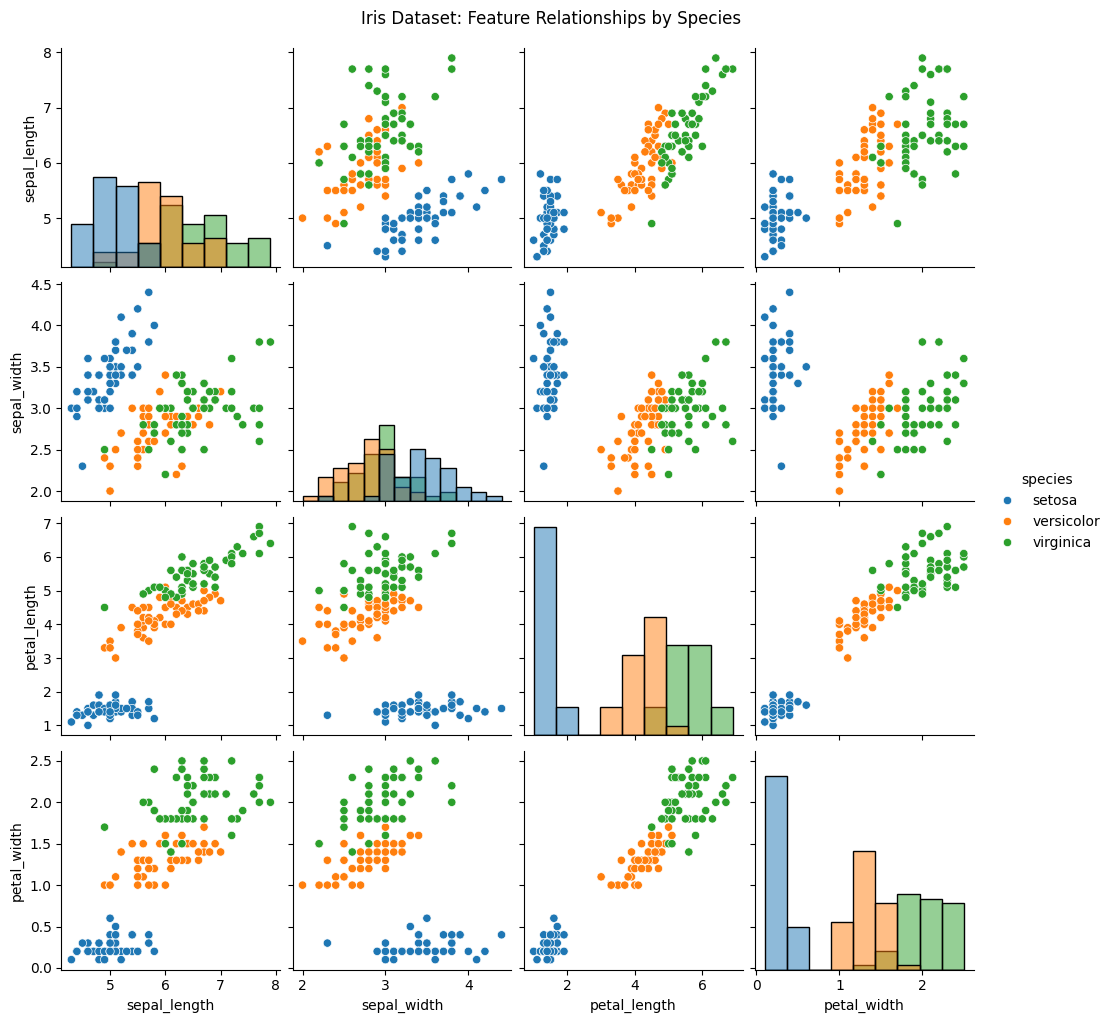

In [20]:
# Visualize relationships between flower measurements

pairplot = sns.pairplot(
    df,
    hue="species",
    diag_kind="hist"
)

pairplot.fig.suptitle(
    "Iris Dataset: Feature Relationships by Species",
    y=1.02
)

plt.show()

In [21]:
# Step 1: Import required tools

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 2: Separate features (X) and target (y)

X = df.drop(columns=["species"])
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Step 3: Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 4: Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Features shape: (150, 4)
Target shape: (150,)

Training samples: 120
Testing samples: 30

Training data scaled: (120, 4)
Testing data scaled: (30, 4)


In [22]:
# Step 1: Import required tools

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 2: Separate features (X) and target (y)

X = df.drop(columns=["species"])
y = df["species"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Step 3: Split the data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# Step 4: Scale the features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nTraining data scaled:", X_train_scaled.shape)
print("Testing data scaled:", X_test_scaled.shape)

Features shape: (150, 4)
Target shape: (150,)

Training samples: 120
Testing samples: 30

Training data scaled: (120, 4)
Testing data scaled: (30, 4)


## Model Training

We will train two classification algorithms:
1. Logistic Regression
2. Decision Tree Classifier

Both models will be trained on the training dataset
and evaluated on the unseen test dataset.

In [23]:
# Step 5: Import Machine Learning algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

# Step 6: Create the models

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Step 7: Train both models

logistic_model.fit(X_train_scaled, y_train)

decision_tree_model.fit(X_train_scaled, y_train)

print("Both models trained successfully!")

# Step 8: Predict flower species on test data

y_pred_logistic = logistic_model.predict(X_test_scaled)

y_pred_tree = decision_tree_model.predict(X_test_scaled)

print("Logistic Regression predictions:")
print(y_pred_logistic)

print("\nDecision Tree predictions:")
print(y_pred_tree)

Both models trained successfully!
Logistic Regression predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']

Decision Tree predictions:
['setosa' 'virginica' 'versicolor' 'versicolor' 'setosa' 'versicolor'
 'setosa' 'setosa' 'virginica' 'versicolor' 'virginica' 'virginica'
 'virginica' 'versicolor' 'setosa' 'setosa' 'setosa' 'versicolor'
 'versicolor' 'virginica' 'setosa' 'virginica' 'versicolor' 'versicolor'
 'virginica' 'virginica' 'versicolor' 'setosa' 'virginica' 'setosa']


In [24]:
# Step 9: Evaluate both classification models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

# Calculate evaluation metrics for Logistic Regression
logistic_accuracy = accuracy_score(y_test, y_pred_logistic)
logistic_precision = precision_score(
    y_test, y_pred_logistic, average="macro"
)
logistic_recall = recall_score(
    y_test, y_pred_logistic, average="macro"
)
logistic_f1 = f1_score(
    y_test, y_pred_logistic, average="macro"
)

# Calculate evaluation metrics for Decision Tree
tree_accuracy = accuracy_score(y_test, y_pred_tree)
tree_precision = precision_score(
    y_test, y_pred_tree, average="macro"
)
tree_recall = recall_score(
    y_test, y_pred_tree, average="macro"
)
tree_f1 = f1_score(
    y_test, y_pred_tree, average="macro"
)

# Compare both models
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy": [logistic_accuracy, tree_accuracy],
    "Precision": [logistic_precision, tree_precision],
    "Recall": [logistic_recall, tree_recall],
    "F1-Score": [logistic_f1, tree_f1]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.9333,0.9333,0.9333,0.9333
1,Decision Tree,0.9333,0.9333,0.9333,0.9333


## Detailed Classification Reports and Confusion Matrices

Logistic Regression - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30


Decision Tree - Classification Report
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



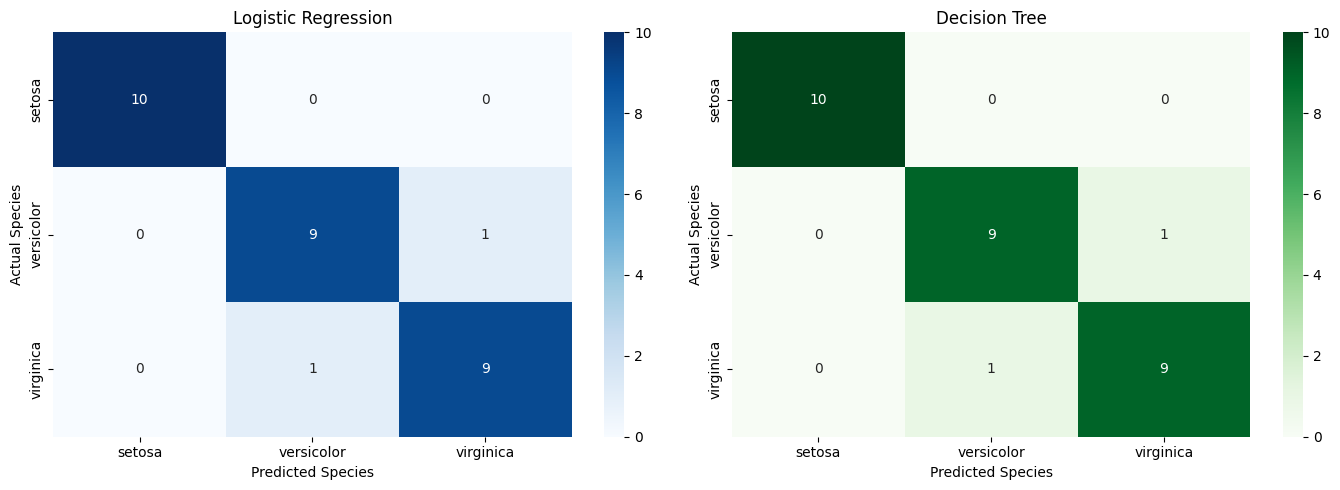

In [25]:
# Step 10: Detailed classification reports and confusion matrices

from sklearn.metrics import classification_report, confusion_matrix

# Print the classification report for Logistic Regression
print("Logistic Regression - Classification Report")
print(classification_report(y_test, y_pred_logistic))

# Print the classification report for Decision Tree
print("\nDecision Tree - Classification Report")
print(classification_report(y_test, y_pred_tree))


# Create confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

class_names = logistic_model.classes_

# Logistic Regression confusion matrix
cm_logistic = confusion_matrix(
    y_test, y_pred_logistic, labels=class_names
)

sns.heatmap(
    cm_logistic,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[0]
)

axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")


# Decision Tree confusion matrix
cm_tree = confusion_matrix(
    y_test, y_pred_tree, labels=class_names
)

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=class_names,
    yticklabels=class_names,
    ax=axes[1]
)

axes[1].set_title("Decision Tree")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.tight_layout()
plt.show()

## Decision Boundary Visualization

Visualize the decision boundaries of Logistic Regression
and Decision Tree using petal length and petal width.

This visualization uses two features so the classification
regions can be displayed in a 2D plot.

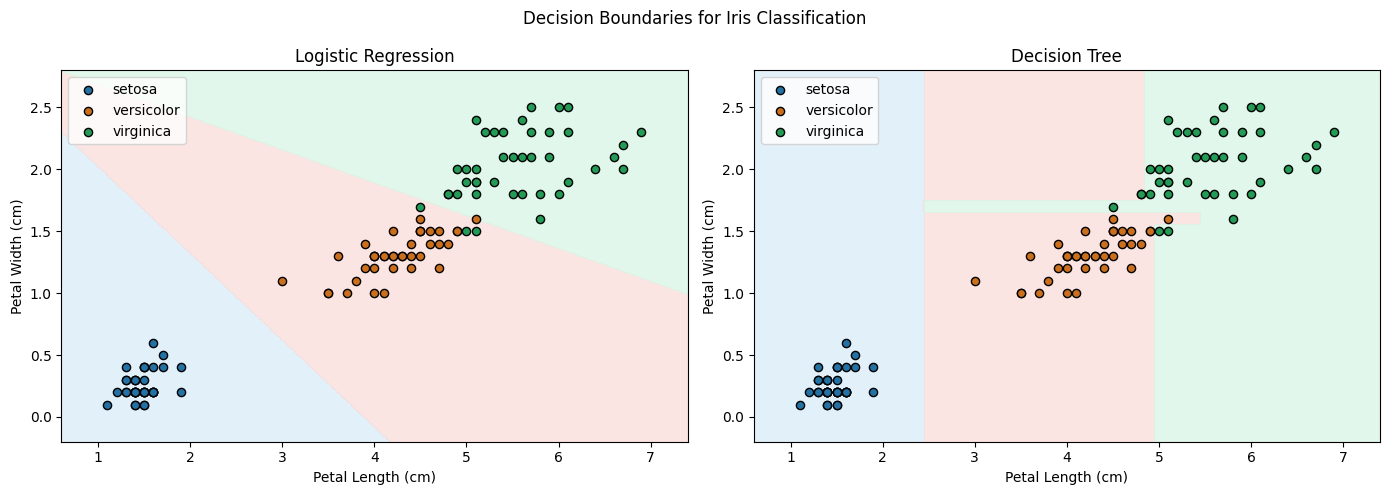

In [26]:
# Step 11: Decision Boundary Visualization

from matplotlib.colors import ListedColormap

# Select two features for 2D visualization
features_2d = ["petal_length", "petal_width"]

X_train_2d = X_train[features_2d]

# Scale the selected features using training data only
scaler_2d = StandardScaler()
X_train_2d_scaled = scaler_2d.fit_transform(X_train_2d)

# Train separate 2-feature models for visualization
logistic_boundary_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

tree_boundary_model = DecisionTreeClassifier(
    random_state=42
)

logistic_boundary_model.fit(X_train_2d_scaled, y_train)
tree_boundary_model.fit(X_train_2d_scaled, y_train)

# Create a grid across the two feature dimensions
x_min = X_train_2d["petal_length"].min() - 0.5
x_max = X_train_2d["petal_length"].max() + 0.5

y_min = X_train_2d["petal_width"].min() - 0.3
y_max = X_train_2d["petal_width"].max() + 0.3

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

# Scale every grid point using the training scaler
grid_points = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=features_2d
)

grid_scaled = scaler_2d.transform(grid_points)

# Predict the species in each grid region
class_names = list(logistic_boundary_model.classes_)
class_to_num = {
    name: index for index, name in enumerate(class_names)
}

Z_logistic = np.array([
    class_to_num[label]
    for label in logistic_boundary_model.predict(grid_scaled)
]).reshape(xx.shape)

Z_tree = np.array([
    class_to_num[label]
    for label in tree_boundary_model.predict(grid_scaled)
]).reshape(xx.shape)

# Plot the decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

region_colors = ListedColormap([
    "#D6EAF8", "#FADBD8", "#D5F5E3"
])

point_colors = {
    "setosa": "#2471A3",
    "versicolor": "#CA6F1E",
    "virginica": "#239B56"
}

boundary_results = [
    (axes[0], Z_logistic, "Logistic Regression"),
    (axes[1], Z_tree, "Decision Tree")
]

for ax, Z, title in boundary_results:
    ax.contourf(
        xx, yy, Z,
        levels=np.arange(-0.5, 3.5, 1),
        cmap=region_colors,
        alpha=0.7
    )

    for species in class_names:
        mask = y_train == species

        ax.scatter(
            X_train_2d.loc[mask, "petal_length"],
            X_train_2d.loc[mask, "petal_width"],
            color=point_colors[species],
            label=species,
            edgecolor="black",
            s=35
        )

    ax.set_title(title)
    ax.set_xlabel("Petal Length (cm)")
    ax.set_ylabel("Petal Width (cm)")
    ax.legend()

plt.suptitle("Decision Boundaries for Iris Classification")
plt.tight_layout()
plt.show()